# Challenge 4: Quantum Correlation Switch

Part A predicts mostly `00` and `11`. Part B adds one X gate on the second qubit and predicts mostly `01` and `10`. Both experiments use exactly two qubits and 100 shots.


In [8]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.primitives import StatevectorSampler

SHOTS = 100


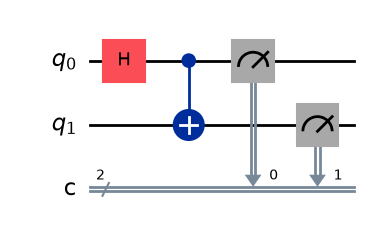

Part A: correlated outcomes {'00': 52, '11': 48}


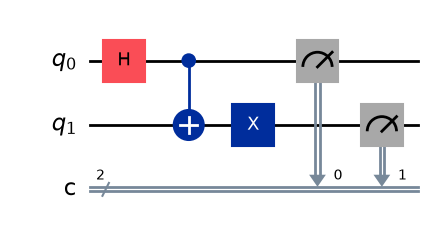

Part B: opposite outcomes {'10': 49, '01': 51}


In [9]:
def run_case(opposite=False):
    circuit = QuantumCircuit(2, 2)
    circuit.h(0)
    circuit.cx(0, 1)
    if opposite:
        circuit.x(1)
    circuit.measure([0, 1], [0, 1])
    counts = StatevectorSampler().run([circuit], shots=SHOTS).result()[0].data.c.get_counts()
    display(circuit.draw(output="mpl"))
    print("Part B: opposite outcomes" if opposite else "Part A: correlated outcomes", counts)
    return counts

part_a = run_case()
part_b = run_case(opposite=True)


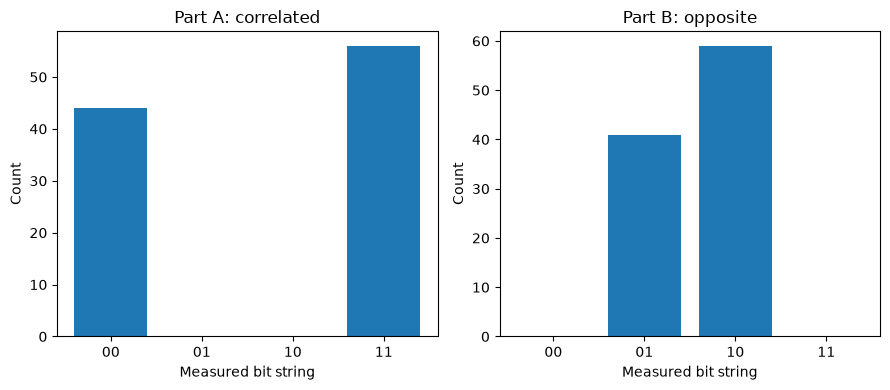

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, title, counts in zip(axes, ["Part A: correlated", "Part B: opposite"], [part_a, part_b]):
    outcomes = ["00", "01", "10", "11"]
    ax.bar(outcomes, [counts.get(bit, 0) for bit in outcomes])
    ax.set_title(title)
    ax.set_xlabel("Measured bit string")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()


## Comparison

Part A uses H followed by CX to prepare `( |00⟩ + |11⟩ ) / √2`. Part B adds X to qubit 1, producing `( |01⟩ + |10⟩ ) / √2`. This extra gate flips the second measurement bit, changing equal outcomes into opposite outcomes. The H-based circuits are probabilistic, so the counts need not be exactly 50/50.
